In [4]:
import zipfile, glob, os, sqlite3
import pandas as pd
from google.colab import files

uploaded = files.upload()          # choose the Olist zip
zipname = list(uploaded.keys())[0]
with zipfile.ZipFile(zipname) as z:
    z.extractall("olist")

conn = sqlite3.connect("olist.db")
for path in glob.glob("olist/*.csv"):
    name = (os.path.basename(path)
            .replace("olist_", "")
            .replace("_dataset.csv", "")
            .replace(".csv", ""))
    pd.read_csv(path).to_sql(name, conn, if_exists="replace", index=False)

def sql(q):
    return pd.read_sql(q, conn)

tables = sql("SELECT name FROM sqlite_master WHERE type='table'")["name"]
for t in tables:
    print(t, sql(f"SELECT COUNT(*) AS n FROM {t}")["n"][0])

Saving archive (4).zip to archive (4).zip
sellers 3095
order_items 112650
order_reviews 99224
product_category_name_translation 71
orders 99441
products 32951
geolocation 1000163
order_payments 103886
customers 99441


In [5]:
# 1. Order status and date range
print(sql("""
SELECT order_status, COUNT(*) AS orders
FROM orders GROUP BY order_status ORDER BY orders DESC;
"""))
print(sql("""
SELECT MIN(order_purchase_timestamp) AS first_order,
       MAX(order_purchase_timestamp) AS last_order
FROM orders;
"""))

# 2. Monthly revenue (delivered orders only)
monthly = sql("""
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(oi.price), 0) AS revenue
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY month;
""")
print(monthly)

# 3. Top 10 categories by revenue
print(sql("""
SELECT COALESCE(t.product_category_name_english,
                p.product_category_name, 'unknown') AS category,
       ROUND(SUM(oi.price), 0) AS revenue,
       COUNT(DISTINCT oi.order_id) AS orders
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t
       ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10;
"""))

  order_status  orders
0    delivered   96478
1      shipped    1107
2     canceled     625
3  unavailable     609
4     invoiced     314
5   processing     301
6      created       5
7     approved       2
           first_order           last_order
0  2016-09-04 21:15:19  2018-10-17 17:30:18
      month  orders   revenue
0   2016-09       1     135.0
1   2016-10     265   40325.0
2   2016-12       1      11.0
3   2017-01     750  111798.0
4   2017-02    1653  234223.0
5   2017-03    2546  359199.0
6   2017-04    2303  340670.0
7   2017-05    3546  489338.0
8   2017-06    3135  421923.0
9   2017-07    3872  481605.0
10  2017-08    4193  554700.0
11  2017-09    4150  607400.0
12  2017-10    4478  648248.0
13  2017-11    7289  987765.0
14  2017-12    5513  726033.0
15  2018-01    7069  924645.0
16  2018-02    6555  826437.0
17  2018-03    7003  953356.0
18  2018-04    6798  973534.0
19  2018-05    6749  977545.0
20  2018-06    6099  856078.0
21  2018-07    6159  867953.0
22  2018-08    

      month  orders   revenue  mom_growth_pct  yoy_growth_pct  avg_order_value
0   2017-01     750  111798.0             NaN             NaN            149.1
1   2017-02    1653  234223.0           109.5             NaN            141.7
2   2017-03    2546  359199.0            53.4             NaN            141.1
3   2017-04    2303  340670.0            -5.2             NaN            147.9
4   2017-05    3546  489338.0            43.6             NaN            138.0
5   2017-06    3135  421923.0           -13.8             NaN            134.6
6   2017-07    3872  481605.0            14.1             NaN            124.4
7   2017-08    4193  554700.0            15.2             NaN            132.3
8   2017-09    4150  607400.0             9.5             NaN            146.4
9   2017-10    4478  648248.0             6.7             NaN            144.8
10  2017-11    7289  987765.0            52.4             NaN            135.5
11  2017-12    5513  726033.0           -26.5       

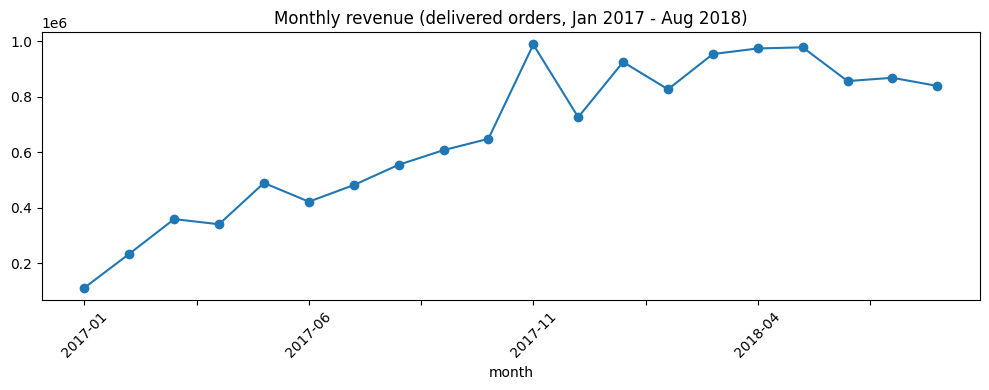

                category    revenue  orders  revenue_per_order  pct_of_revenue
0          health_beauty  1233132.0    8647              142.6             9.3
1          watches_gifts  1166177.0    5495              212.2             8.8
2         bed_bath_table  1023435.0    9272              110.4             7.7
3         sports_leisure   954853.0    7530              126.8             7.2
4  computers_accessories   888725.0    6530              136.1             6.7
5        furniture_decor   711928.0    6307              112.9             5.4
6             housewares   615629.0    5743              107.2             4.7
7             cool_stuff   610204.0    3559              171.5             4.6
8                   auto   578967.0    3810              152.0             4.4
9                   toys   471286.0    3804              123.9             3.6


In [7]:
monthly = sql("""
WITH m AS (
  SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
         COUNT(DISTINCT o.order_id) AS orders,
         SUM(oi.price) AS revenue
  FROM orders o
  JOIN order_items oi ON o.order_id = oi.order_id
  WHERE o.order_status = 'delivered'
    AND o.order_purchase_timestamp >= '2017-01-01'
    AND o.order_purchase_timestamp <  '2018-09-01'
  GROUP BY month
)
SELECT month, orders, ROUND(revenue, 0) AS revenue,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month))
             / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct,
       ROUND(100.0 * (revenue - LAG(revenue, 12) OVER (ORDER BY month))
             / LAG(revenue, 12) OVER (ORDER BY month), 1) AS yoy_growth_pct,
       ROUND(revenue / orders, 1) AS avg_order_value
FROM m ORDER BY month;
""")
print(monthly)

import matplotlib.pyplot as plt
monthly.plot(x="month", y="revenue", kind="line", marker="o", figsize=(10, 4), legend=False)
plt.title("Monthly revenue (delivered orders, Jan 2017 - Aug 2018)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(sql("""
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       ROUND(SUM(oi.price), 0) AS revenue,
       COUNT(DISTINCT oi.order_id) AS orders,
       ROUND(SUM(oi.price) / COUNT(DISTINCT oi.order_id), 1) AS revenue_per_order,
       ROUND(100.0 * SUM(oi.price) / SUM(SUM(oi.price)) OVER (), 1) AS pct_of_revenue
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10;
"""))

In [8]:
cust = sql("""
SELECT c.customer_unique_id,
       COUNT(DISTINCT o.order_id) AS orders,
       MIN(o.order_purchase_timestamp) AS first_order,
       SUM(oi.price) AS spend
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_items oi ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY c.customer_unique_id
""")

print("Unique customers:", len(cust))
print(cust["orders"].value_counts().sort_index())
print("Repeat customer rate %:", round((cust["orders"] > 1).mean() * 100, 1))
print("Revenue share from repeat customers %:",
      round(cust.loc[cust["orders"] > 1, "spend"].sum() / cust["spend"].sum() * 100, 1))

Unique customers: 93104
orders
1     90315
2      2562
3       180
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64
Repeat customer rate %: 3.0
Revenue share from repeat customers %: 5.5


In [9]:
oc = sql("""
SELECT c.customer_unique_id, o.order_purchase_timestamp AS ts
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""")

oc["ts"] = pd.to_datetime(oc["ts"])
oc["order_month"] = oc["ts"].dt.to_period("M")
oc["cohort"] = oc.groupby("customer_unique_id")["order_month"].transform("min")
oc["age"] = (oc["order_month"] - oc["cohort"]).apply(lambda x: x.n)

cohort = (oc.groupby(["cohort", "age"])["customer_unique_id"]
            .nunique().unstack(fill_value=0))
retention = cohort.div(cohort[0], axis=0) * 100

print(cohort[0])                    # cohort sizes
print(retention.iloc[:, :7].round(2))
print("Avg month-1 retention %:", round(retention[1].iloc[:-1].mean(), 2))

cohort
2017-01     718
2017-02    1628
2017-03    2503
2017-04    2257
2017-05    3451
2017-06    3037
2017-07    3753
2017-08    4057
2017-09    4005
2017-10    4328
2017-11    7061
2017-12    5338
2018-01    6843
2018-02    6288
2018-03    6775
2018-04    6582
2018-05    6508
2018-06    5879
2018-07    5949
2018-08    6144
Freq: M, Name: 0, dtype: int64
age          0     1     2     3     4     5     6
cohort                                            
2017-01  100.0  0.28  0.28  0.14  0.42  0.14  0.42
2017-02  100.0  0.18  0.31  0.12  0.43  0.12  0.25
2017-03  100.0  0.44  0.36  0.40  0.36  0.16  0.16
2017-04  100.0  0.62  0.22  0.18  0.27  0.27  0.35
2017-05  100.0  0.46  0.46  0.29  0.29  0.32  0.41
2017-06  100.0  0.49  0.40  0.43  0.30  0.40  0.36
2017-07  100.0  0.53  0.35  0.24  0.29  0.21  0.32
2017-08  100.0  0.69  0.35  0.27  0.35  0.52  0.30
2017-09  100.0  0.70  0.55  0.27  0.45  0.22  0.22
2017-10  100.0  0.72  0.25  0.09  0.23  0.21  0.21
2017-11  100.0  0.57  0.37  0.

Orders analyzed: 95560
Late delivery rate %: 8.0
       count  mean
late              
False  87902  4.30
True    7658  2.57
                     count  mean  pct_1_2_star
band                                          
early 7+             70673  4.32           8.9
early 0-7 / on time  17229  4.20          10.2
late 1-3              2635  3.77          19.1
late 4-7              1773  2.32          61.3
late 8+               3250  1.73          78.3


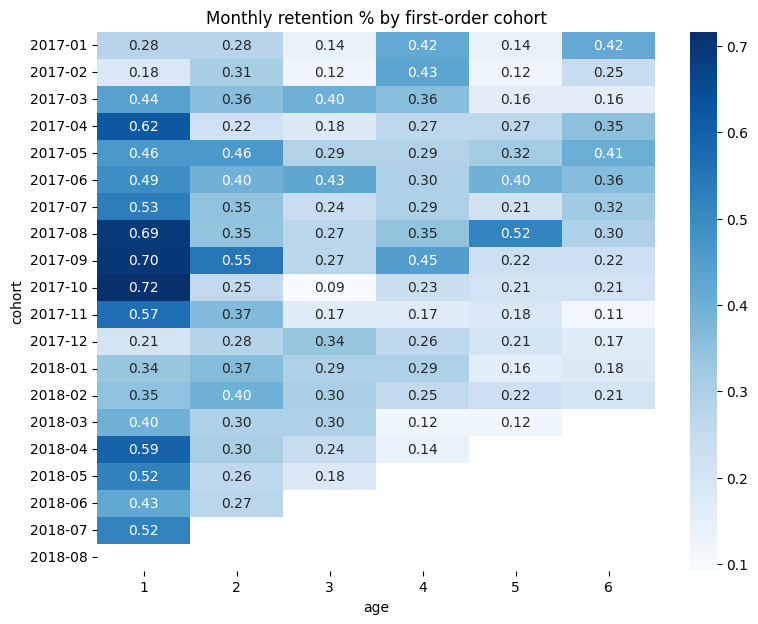

In [10]:
d = sql("""
SELECT o.order_id, c.customer_unique_id, c.customer_state,
       julianday(o.order_delivered_customer_date)
         - julianday(o.order_estimated_delivery_date) AS days_vs_estimate,
       r.review_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN (SELECT order_id, AVG(review_score) AS review_score
      FROM order_reviews GROUP BY order_id) r ON o.order_id = r.order_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""")

d["late"] = d["days_vs_estimate"] > 0
print("Orders analyzed:", len(d))
print("Late delivery rate %:", round(d["late"].mean() * 100, 1))
print(d.groupby("late")["review_score"].agg(["count", "mean"]).round(2))

d["band"] = pd.cut(d["days_vs_estimate"],
                   [-999, -7, 0, 3, 7, 999],
                   labels=["early 7+", "early 0-7 / on time", "late 1-3", "late 4-7", "late 8+"])
band = d.groupby("band", observed=True)["review_score"].agg(["count", "mean"]).round(2)
band["pct_1_2_star"] = d.groupby("band", observed=True)["review_score"].apply(lambda s: (s <= 2).mean() * 100).round(1)
print(band)

# Bonus: retention heatmap for your README
import seaborn as sns
plt.figure(figsize=(9, 7))
sns.heatmap(retention.iloc[:, 1:7].mask(retention.iloc[:, 1:7] == 0), annot=True, fmt=".2f", cmap="Blues")
plt.title("Monthly retention % by first-order cohort")
plt.show()

In [11]:
f = sql("""
SELECT c.customer_unique_id, c.customer_state, o.order_purchase_timestamp AS ts,
       julianday(o.order_delivered_customer_date)
         - julianday(o.order_estimated_delivery_date) AS days_vs_estimate
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""").sort_values("ts")

g = f.groupby("customer_unique_id")
first = g.first()
first["n_orders"] = g.size()
first["late"] = first["days_vs_estimate"] > 0
first["repeat"] = first["n_orders"] > 1

# only customers with at least ~6 months of follow-up time
fu = first[first["ts"] < "2018-03-01"]
res = fu.groupby("late")["repeat"].agg(["count", "mean"])
res["mean"] = (res["mean"] * 100).round(2)
print(res)

# Which states have the worst late-delivery rates?
st = f.assign(late=f["days_vs_estimate"] > 0).groupby("customer_state")["late"].agg(["count", "mean"])
st["mean"] = (st["mean"] * 100).round(1)
print(st[st["count"] > 500].sort_values("mean", ascending=False).head(6))

       count  mean
late              
False  51007  4.05
True    4258  3.10
                count  mean
customer_state             
MA                713  19.6
CE               1273  15.4
BA               3253  14.0
RJ              12310  13.5
PA                942  12.4
ES               1992  12.2


In [13]:
import os, shutil
os.makedirs("out", exist_ok=True)

monthly.to_csv("out/monthly.csv", index=False)

sql("""
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       ROUND(SUM(oi.price), 0) AS revenue,
       COUNT(DISTINCT oi.order_id) AS orders,
       ROUND(SUM(oi.price) / COUNT(DISTINCT oi.order_id), 1) AS revenue_per_order
FROM order_items oi
JOIN orders o ON oi.order_id = o.order_id
JOIN products p ON oi.product_id = p.product_id
LEFT JOIN product_category_name_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category ORDER BY revenue DESC LIMIT 15;
""").to_csv("out/categories.csv", index=False)

ret = retention.iloc[:, 1:7].round(2).copy()
ret = ret.mask(ret == 0)
ret.index = ret.index.astype(str)
ret.columns = [f"m{c}" for c in ret.columns]
ret.reset_index().to_csv("out/retention.csv", index=False)

b = band.reset_index()
b["band"] = ["1 early 7+", "2 on time / early 0-7", "3 late 1-3", "4 late 4-7", "5 late 8+"]
b.to_csv("out/delivery_bands.csv", index=False)

st[st["count"] > 500].reset_index().to_csv("out/state_late.csv", index=False)
res.reset_index().to_csv("out/repeat_by_late.csv", index=False)

pd.DataFrame([{
    "orders": int(monthly["orders"].sum()),
    "revenue": float(monthly["revenue"].sum()),
    "customers": len(cust),
    "repeat_pct": round((cust["orders"] > 1).mean() * 100, 1),
    "late_pct": round(d["late"].mean() * 100, 1),
    "avg_review": round(d["review_score"].mean(), 2),
}]).to_csv("out/kpis.csv", index=False)

shutil.make_archive("olist_out", "zip", "out")
files.download("olist_out.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>